In [ ]:
%pip install -q landingai pillow matplotlib

from PIL import Image
from landingai.predict import Predictor
import matplotlib.pyplot as plt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.11.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
google-adk 2.7.1 requires tenacity<10,>=9, but you have tenacity 8.5.0 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
shap 0.54.1 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
dm-t

In [ ]:
%pip install --no-cache-dir --force-reinstall numpy==2.2.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 49.3 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
landingai 0.3.49 requires numpy<2.0.0,>=1.21.0, but you have numpy 2.2.6 which is incompatible.


In [ ]:
import numpy as np
from PIL import Image
from landingai.predict import Predictor
import matplotlib.pyplot as plt

print("All imports successful!")

All imports successful!


Saving YM.NE3.51.png to YM.NE3.51.png


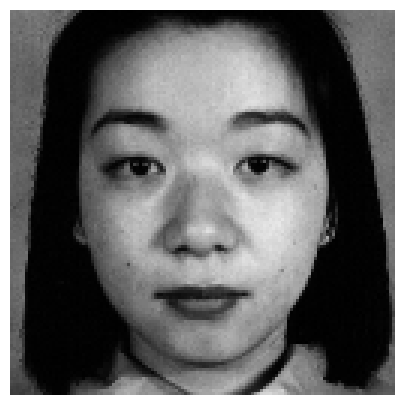

In [ ]:
endpoint_id = "89cf5d17-7238-49cb-bdb7-d654c15237a8"
api_key = "land_sk_wMRSaykMtiMVT2Yyx4q1pdk1oa0ciS6os7y88pi7aG6WyMmfOg"

predictor = Predictor(endpoint_id, api_key=api_key)


from google.colab import files

uploaded = files.upload()
image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
predictions = predictor.predict(image)

if predictions:
    best_prediction = max(predictions, key=lambda x: x.score)

    emotion = best_prediction.label_name
    confidence = best_prediction.score

    print("Detected Expression:", emotion)
    print("Confidence:", round(confidence * 100, 2), "%")
else:
    emotion = "Unknown"
    confidence = 0

    print("No expression detected.")

Detected Expression: neutral
Confidence: 98.38 %


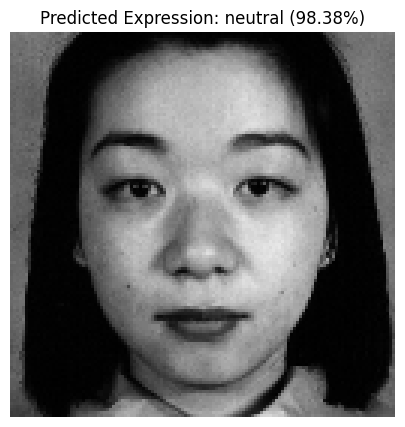

Cognitive Assistant:
Your facial expression appears neutral. How are you feeling today?


In [ ]:
responses = {
    "happy": "You seem to be displaying a happy expression. Keep enjoying the moment!",
    "sad": "You seem to be displaying a sad expression. Remember to take care of yourself.",
    "angry": "You seem to be displaying an angry expression. Taking a moment to relax may help.",
    "fear": "You seem to be displaying a fearful expression. Take a breath and try to stay calm.",
    "surprise": "You seem to be displaying a surprised expression. Something unexpected?",
    "disgust": "You seem to be displaying an expression of disgust. Is something bothering you?",
    "neutral": "Your facial expression appears neutral. How are you feeling today?"
}

if confidence < 0.50:
    response = "I couldn't confidently identify the facial expression."
else:
    response = responses.get(
        emotion.lower(),
        "I detected a facial expression, but couldn't identify its category."
    )

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.axis("off")
plt.title(f"Predicted Expression: {emotion} ({confidence * 100:.2f}%)")
plt.show()

print("Cognitive Assistant:")
print(response)